In [15]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from IPython.display import Audio, display

In [24]:
DATA_DIR = Path("data/audio")

CLEAN_DIR = DATA_DIR / "clean"
DIRTY_DIR = DATA_DIR / "dirty"

In [ ]:
audio_extensions = {".wav", ".mp3", ".flac", ".ogg", ".m4a"}

#This gathers every clean file
cleanFiles = [
    path for path in CLEAN_DIR.rglob("*")
    if path.suffix.lower() in audio_extensions
]

print(f"Number of clean recordings: {len(cleanFiles)}")

Number of clean recordings: 92


In [ ]:
#This creates the metadata, this will be updated later for actual chord info
def createMeta(fileList, label, labelName):
    records= []

    for filePath in fileList:
        fileName = filePath.name
        stem = filePath.stem
        chordName = re.sub(r"\d+$", "", stem)
        records.append({
            "filename": fileName,
            "filepath" : str(filePath),
            "chord" : chordName,
            "label" : label,
            "labelName" : labelName
        })

    return records


In [27]:
cleanRecords = createMeta(cleanFiles, label=1, labelName="clean")

#Add dirtyRecords when recorded
records = cleanRecords 
df = pd.DataFrame(records)
df.head()


,filename,filepath,chord,label,labelName
0,A1.wav,data\audio\clean\A1.wav,A,1,clean
1,A10.wav,data\audio\clean\A10.wav,A,1,clean
2,A11.wav,data\audio\clean\A11.wav,A,1,clean
3,A12.wav,data\audio\clean\A12.wav,A,1,clean
4,A13.wav,data\audio\clean\A13.wav,A,1,clean


In [ ]:
#Gets all the chords loaded in the dataset
print("Number of unique chords:")
print(df["chord"].nunique())

print("\nChords represented:")
print(sorted(df["chord"].unique()))

Number of unique chords:
8

Chords represented:
['A', 'Am', 'C', 'D', 'Dm', 'E', 'Em', 'G']


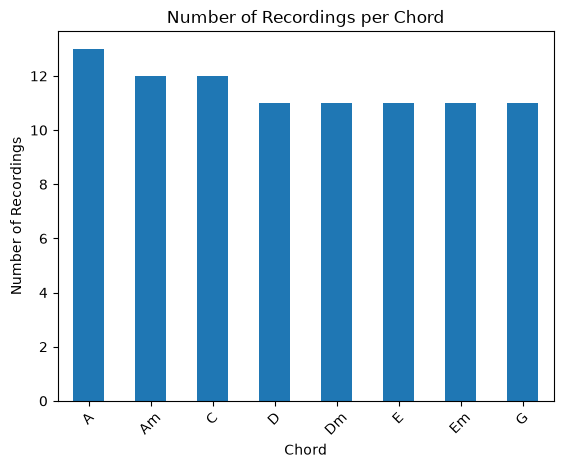

In [ ]:
#Prints distribution of chords based on the number of recordings for each
chord_counts = df["chord"].value_counts()
chord_counts.plot(kind="bar")

plt.title("Number of Recordings per Chord")
plt.xlabel("Chord")
plt.ylabel("Number of Recordings")
plt.xticks(rotation=45)
plt.show()